# Act 04 - Indicadores técnicos

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import load_ohlcv
from indicators import (add_indicators, nan_report, check_lookahead,
                        centered_ma, zscore_muestra,
                        sma, ema, rsi, atr, macd, adx, obv, vwap, stochastic)
from plots import plot_overlays, plot_rsi, plot_macd, plot_panel, plot_corr, guardar

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
%matplotlib inline

## 1. Los datos

In [2]:
df = load_ohlcv()
print(df.shape)
print(df.index.min(), "->", df.index.max())
df.head()

(2446, 5)
2020-01-01 00:00:00 -> 2026-09-11 00:00:00


,open,high,low,close,volume
Date,,,,,
2020-01-01,7194.892090,7254.330566,7174.944336,7200.174316,18565664997
2020-01-02,7202.551270,7212.155273,6935.270020,6985.470215,20802083465
2020-01-03,6984.428711,7413.715332,6914.996094,7344.884277,28111481032
2020-01-04,7345.375488,7427.385742,7309.514160,7410.656738,18444271275
2020-01-05,7410.451660,7544.497070,7400.535645,7411.317383,19725074095


In [3]:
df.describe().round(2)

,open,high,low,close,volume
count,2446.00,2446.00,2446.00,2446.00,2.446000e+03
mean,49791.19,50741.24,48786.33,49818.13,3.635353e+10
std,30869.91,31324.04,30374.64,30862.76,2.109041e+10
min,5002.58,5331.83,4106.98,4970.79,5.331173e+09
25%,23743.84,24205.18,23243.77,23776.68,2.239288e+10
50%,43780.53,44384.91,42780.34,43785.30,3.217671e+10
75%,68414.91,69688.69,67162.88,68478.86,4.489787e+10
max,124752.14,126198.07,123196.05,124752.53,3.509679e+11


In [4]:
print("nulos:", int(df.isna().sum().sum()))
print("gaps > 1 dia:", int((df.index.to_series().diff() > pd.Timedelta("1D")).sum()))

nulos: 0
gaps > 1 dia: 0


## 2. Aplicar add_indicators

In [5]:
out = add_indicators(df)
print(df.shape, "->", out.shape)
[c for c in out.columns if c not in df.columns]

(2446, 5) -> (2446, 25)


['sma_10',
 'sma_20',
 'sma_100',
 'ema_20',
 'bb_high',
 'bb_mid',
 'bb_low',
 'bb_pct',
 'atr_14',
 'rsi_14',
 'macd',
 'macd_signal',
 'macd_hist',
 'stoch_k',
 'stoch_d',
 'adx',
 'adx_pos',
 'adx_neg',
 'obv',
 'vwap_14']

In [6]:
b = out.dropna(subset=["bb_low", "bb_high"])
checks = {
    "sma_20 == close.rolling(20).mean()": np.allclose(
        out["sma_20"].dropna(), df["close"].rolling(20).mean().dropna()),
    "bb_mid == sma_20": np.allclose(out["bb_mid"].dropna(), out["sma_20"].dropna()),
    "rsi_14 entre 0 y 100": bool(out["rsi_14"].dropna().between(0, 100).all()),
    "stoch_k entre 0 y 100": bool(out["stoch_k"].dropna().between(0, 100).all()),
    "atr_14 > 0": bool((out["atr_14"].dropna() > 0).all()),
    "bb_low <= bb_mid <= bb_high": bool(
        ((b.bb_low <= b.bb_mid) & (b.bb_mid <= b.bb_high)).all()),
}
for k, v in checks.items():
    print(f"{'OK ' if v else 'MAL'}  {k}")

OK   sma_20 == close.rolling(20).mean()
OK   bb_mid == sma_20
OK   rsi_14 entre 0 y 100
OK   stoch_k entre 0 y 100
OK   atr_14 > 0
OK   bb_low <= bb_mid <= bb_high


## 3. Valores nulos

In [7]:
nan_report(out)

,n_nan,pct_nan,first_valid,nan_interior
open,0,0.00,2020-01-01,0
high,0,0.00,2020-01-01,0
low,0,0.00,2020-01-01,0
close,0,0.00,2020-01-01,0
volume,0,0.00,2020-01-01,0
sma_10,9,0.37,2020-01-10,0
sma_20,19,0.78,2020-01-20,0
sma_100,99,4.05,2020-04-09,0
ema_20,19,0.78,2020-01-20,0
bb_high,19,0.78,2020-01-20,0


Todos los NaN estan al inicio y corresponden al calentamiento de cada ventana.
La `sma_100` necesita 99 barras, el `macd_signal` 33 y la `sma_10` solo 9.

La columna `nan_interior` cuenta los NaN posteriores al primer dato valido. Da
0 en las 25 columnas, asi que no hay huecos a media serie.

In [8]:
z = (out == 0).sum()
z[z > 0]

stoch_k    7
dtype: int64

Los 7 ceros que quedan en `stoch_k` si son validos. %K = 0 significa que el
cierre toco el minimo de la ventana, y ocurre en fondos reales como 2021-05-12
o 2022-06-12.

## 4. Graficas

Con las 2,446 barras juntas no se distingue nada, asi que uso el tramo 2024-01
a 2025-06, que tiene subida, techo y correccion.

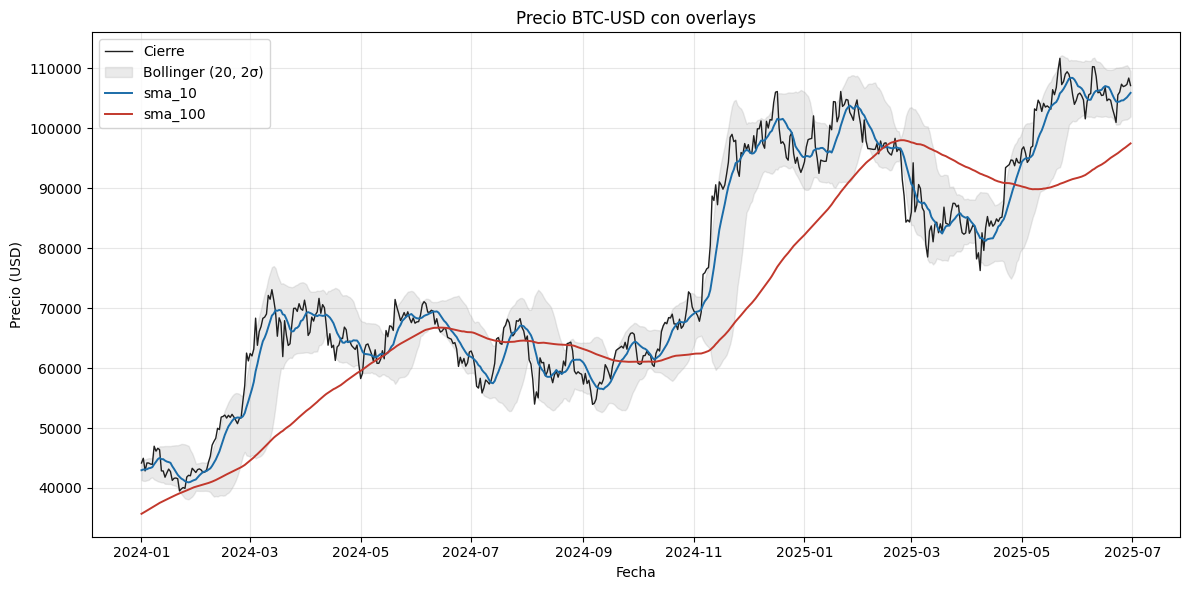

In [9]:
INI, FIN = "2024-01-01", "2025-06-30"
sub = out.loc[INI:FIN]

fig = plot_overlays(out, ("sma_10", "sma_100"), start=INI, end=FIN)
guardar(fig, "outputs/01_overlays.png")
fig

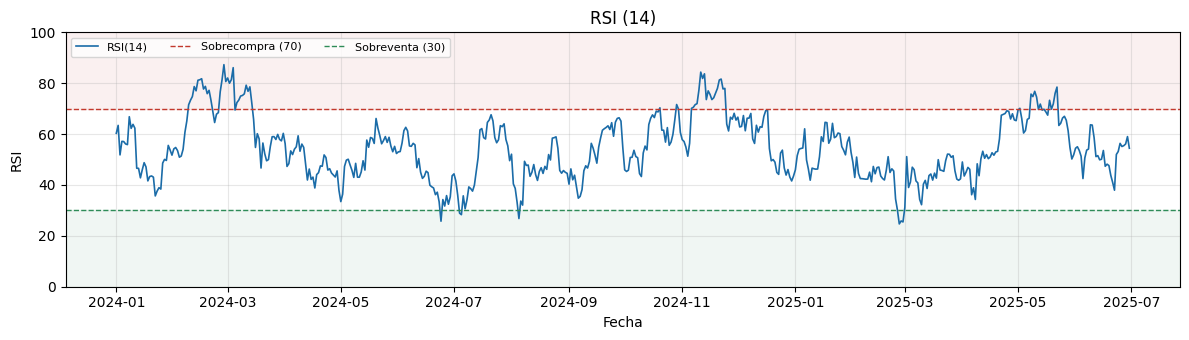

In [10]:
fig = plot_rsi(sub)
guardar(fig, "outputs/02_rsi.png")
fig

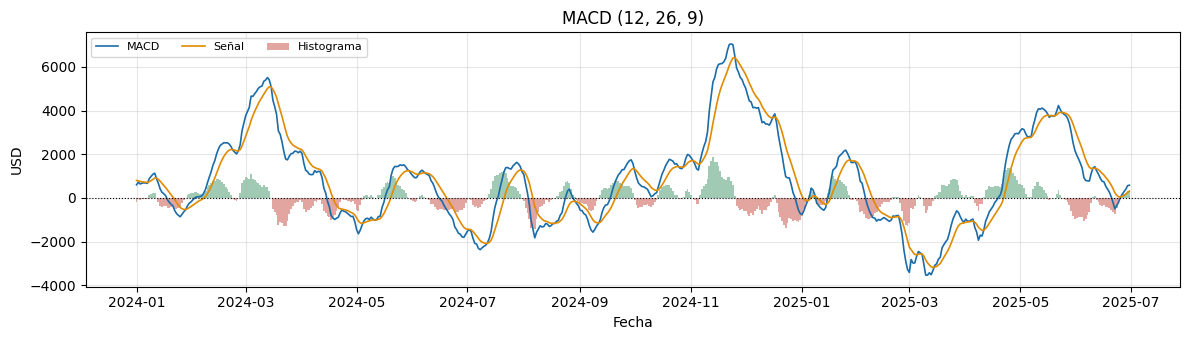

In [11]:
fig = plot_macd(sub)
guardar(fig, "outputs/03_macd.png")
fig

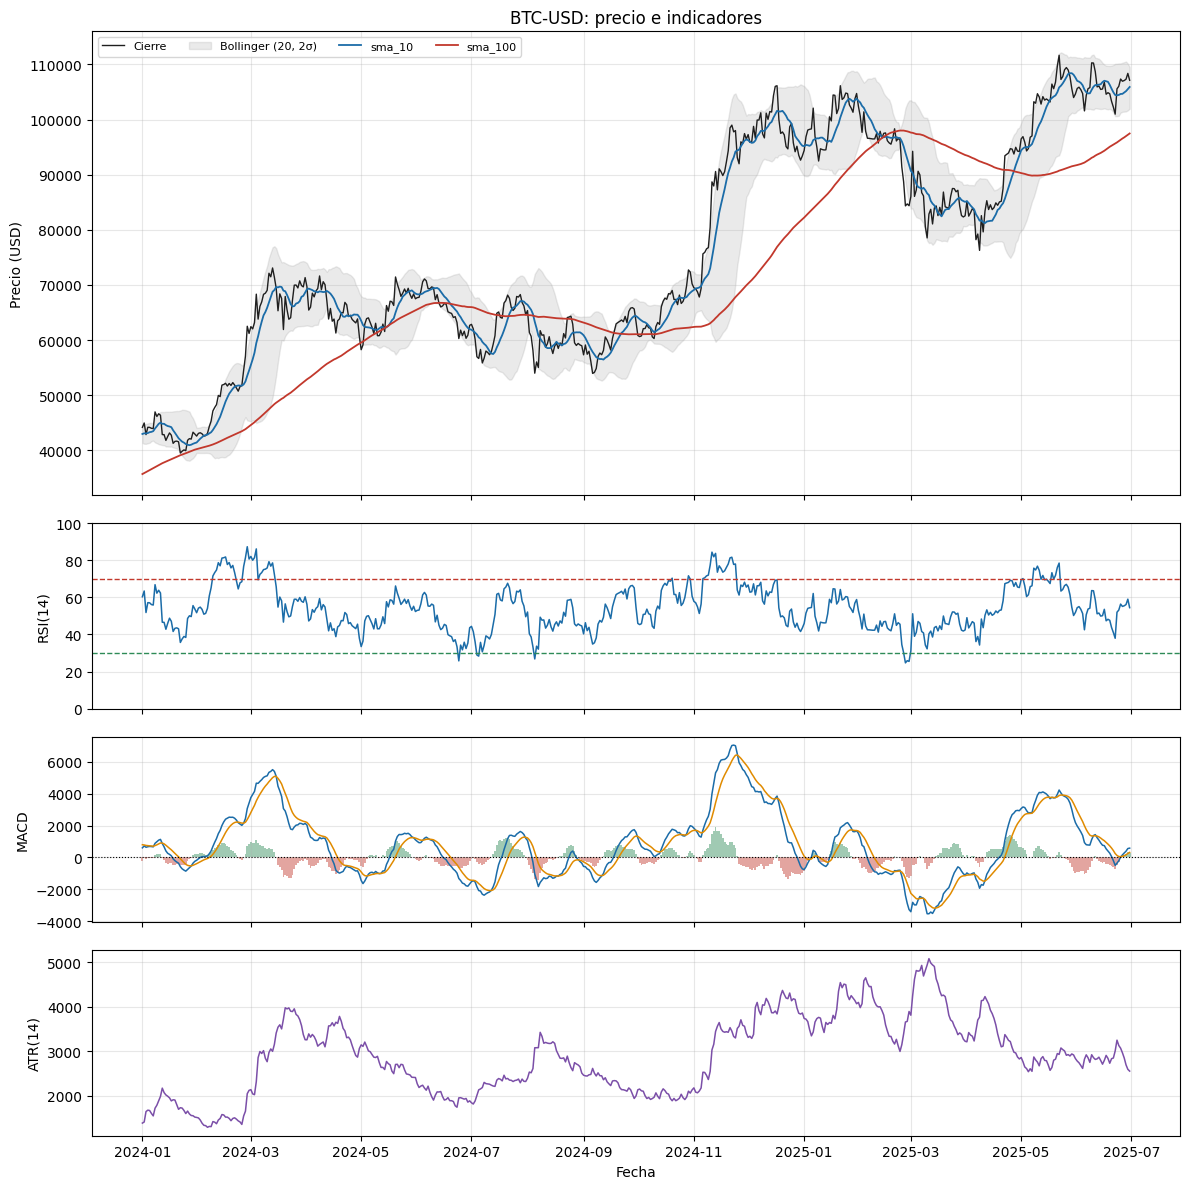

In [12]:
fig = plot_panel(sub)
guardar(fig, "outputs/04_panel.png")
fig

## Pregunta 1: sma_10 vs sma_100

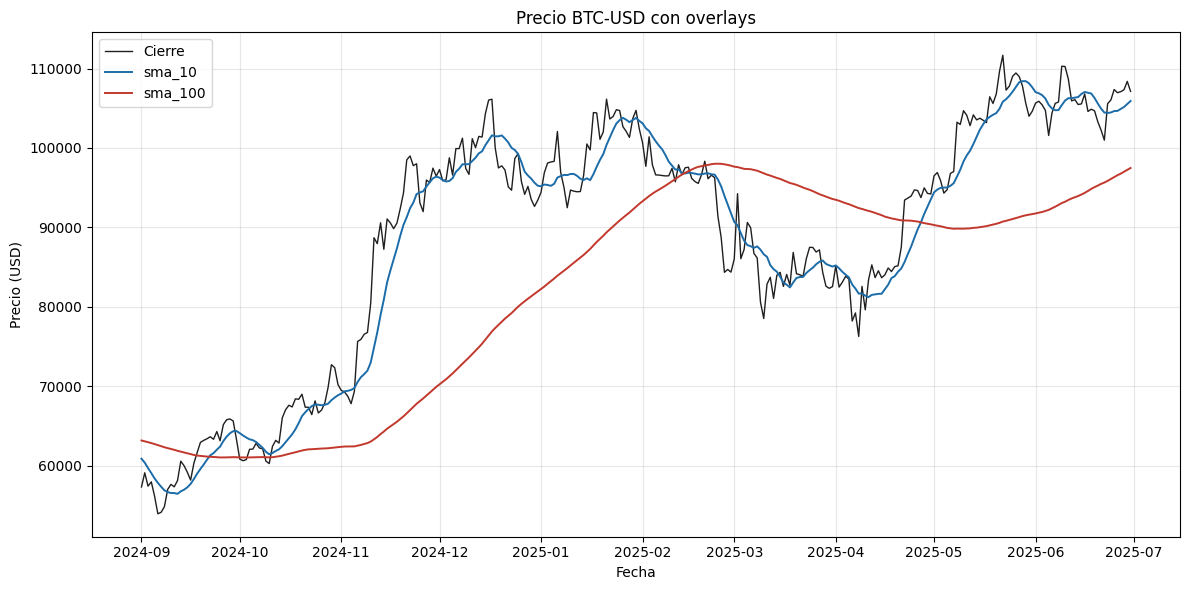

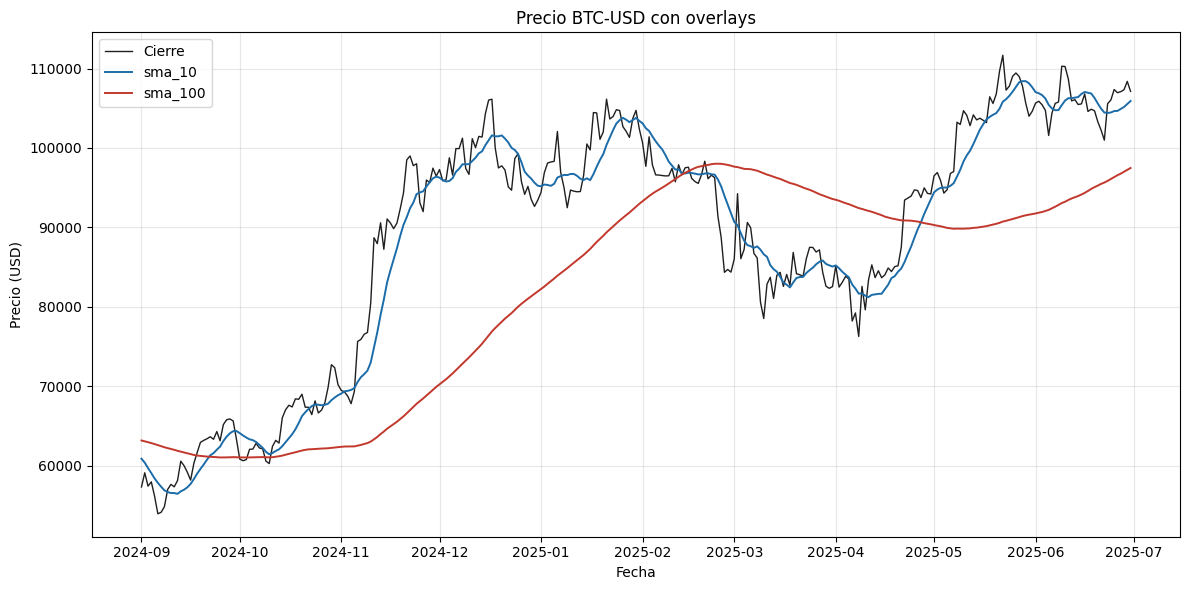

In [13]:
fig = plot_overlays(out, ("sma_10", "sma_100"), bandas=False,
                    start="2024-09-01", end="2025-06-30")
fig

In [14]:
d = out.dropna(subset=["sma_10", "sma_100"])

for c in ["sma_10", "sma_100"]:
    lag = max(range(0, 80), key=lambda L: d["close"].shift(L).corr(d[c]))
    n = int(c.split("_")[1])
    print(f"{c:8s}  rezago = {lag:2d} dias   (teorico (n-1)/2 = {(n - 1) / 2:.1f})")

sma_10    rezago =  4 dias   (teorico (n-1)/2 = 4.5)
sma_100   rezago = 50 dias   (teorico (n-1)/2 = 49.5)


El resultado coincide con la teoria: una SMA de ventana n rezaga alrededor de
(n-1)/2 barras. La `sma_10` va 4 dias atras del precio y la `sma_100` va 50.

Para los movimientos falsos se cuenta cuantas veces el precio cruza cada media,
porque cada cruce seria una señal de entrada o salida.

In [15]:
def cruces(precio, ma):
    s = np.sign(precio - ma)
    return int((s.diff() != 0).sum() - 1)


años = (d.index[-1] - d.index[0]).days / 365.25
n10, n100 = cruces(d["close"], d["sma_10"]), cruces(d["close"], d["sma_100"])

print(f"periodo: {años:.1f} años")
print(f"cruces con sma_10 : {n10:4d}  ({n10 / años:5.1f} por año)")
print(f"cruces con sma_100: {n100:4d}  ({n100 / años:5.1f} por año)")
print(f"la sma_10 cruza {n10 / n100:.1f} veces mas")

periodo: 6.4 años
cruces con sma_10 :  409  ( 63.7 por año)
cruces con sma_100:   87  ( 13.5 por año)
la sma_10 cruza 4.7 veces mas


In [16]:
for c in ["sma_10", "sma_100"]:
    s = np.sign(d["close"] - d[c])
    ch = s[s.diff() != 0]
    dur = ch.index.to_series().diff().dt.days.dropna()
    w = int((dur <= 5).sum())
    print(f"{c:8s}: {w:3d} de {len(dur):3d} señales ({100 * w / len(dur):2.0f}%) "
          f"se voltean en 5 dias o menos")

sma_10  : 245 de 409 señales (60%) se voltean en 5 dias o menos
sma_100 :  46 de  87 señales (53%) se voltean en 5 dias o menos


### Respuesta

| | sma_10 | sma_100 |
|---|---|---|
| rezago | 4 dias | 50 dias |
| cruces | 409 | 87 |
| señales que mueren en 5 dias | 60% | 53% |

La `sma_10` reacciona 46 dias antes. A cambio cruza 4.7 veces mas seguido y 6
de cada 10 señales se revierten en menos de una semana. En una estrategia real
esos 245 cruces falsos serian 245 veces pagando comision y spread sin capturar
nada.

La `sma_100` casi no tiene ruido pero llega muy tarde. En la caida de febrero y
marzo de 2025 la `sma_10` ya venia bajando desde enero, mientras que la
`sma_100` seguia subiendo y no hizo techo hasta marzo.

Ninguna es mejor que la otra. Es un intercambio entre rezago y ruido: si operar
sale caro conviene la ventana larga, y si se busca capturar movimientos cortos,
la ventana corta.

## Pregunta 2: donde se equivoca cada indicador

In [17]:
fwd = out["close"].shift(-20) / out["close"] - 1

### RSI

In [18]:
sig = out[out["rsi_14"] > 70].copy()
sig["fwd20"] = fwd[sig.index]
malas = sig[sig["fwd20"] > 0.15]

print(f"señales de RSI > 70: {len(sig)}")
print(f"seguidas de +15% en 20 dias: {len(malas)} ({100 * len(malas) / len(sig):.0f}%)")
malas.sort_values("fwd20", ascending=False)[["close", "rsi_14", "adx", "fwd20"]].head()

señales de RSI > 70: 278
seguidas de +15% en 20 dias: 69 (25%)


,close,rsi_14,adx,fwd20
Date,,,,
2020-12-20,23477.294922,75.512156,38.743799,0.714616
2020-12-19,23869.832031,79.453318,36.612455,0.709170
2020-12-18,23137.960938,77.412291,34.361095,0.701578
2020-12-17,22805.162109,76.423394,32.254933,0.614738
2020-12-16,21310.597656,71.157682,29.986758,0.595095


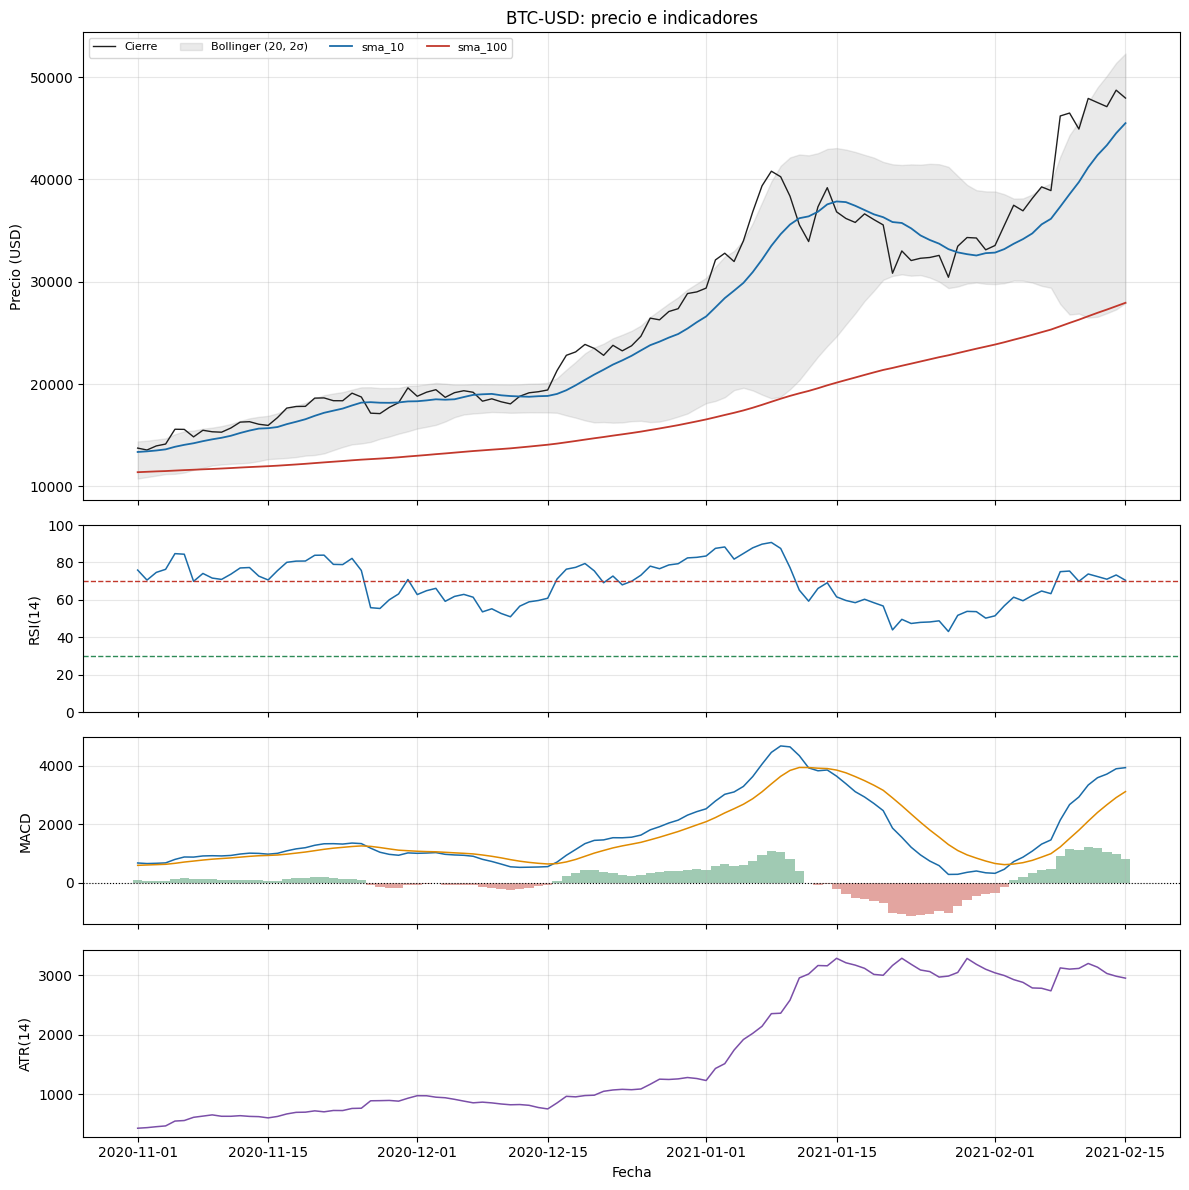

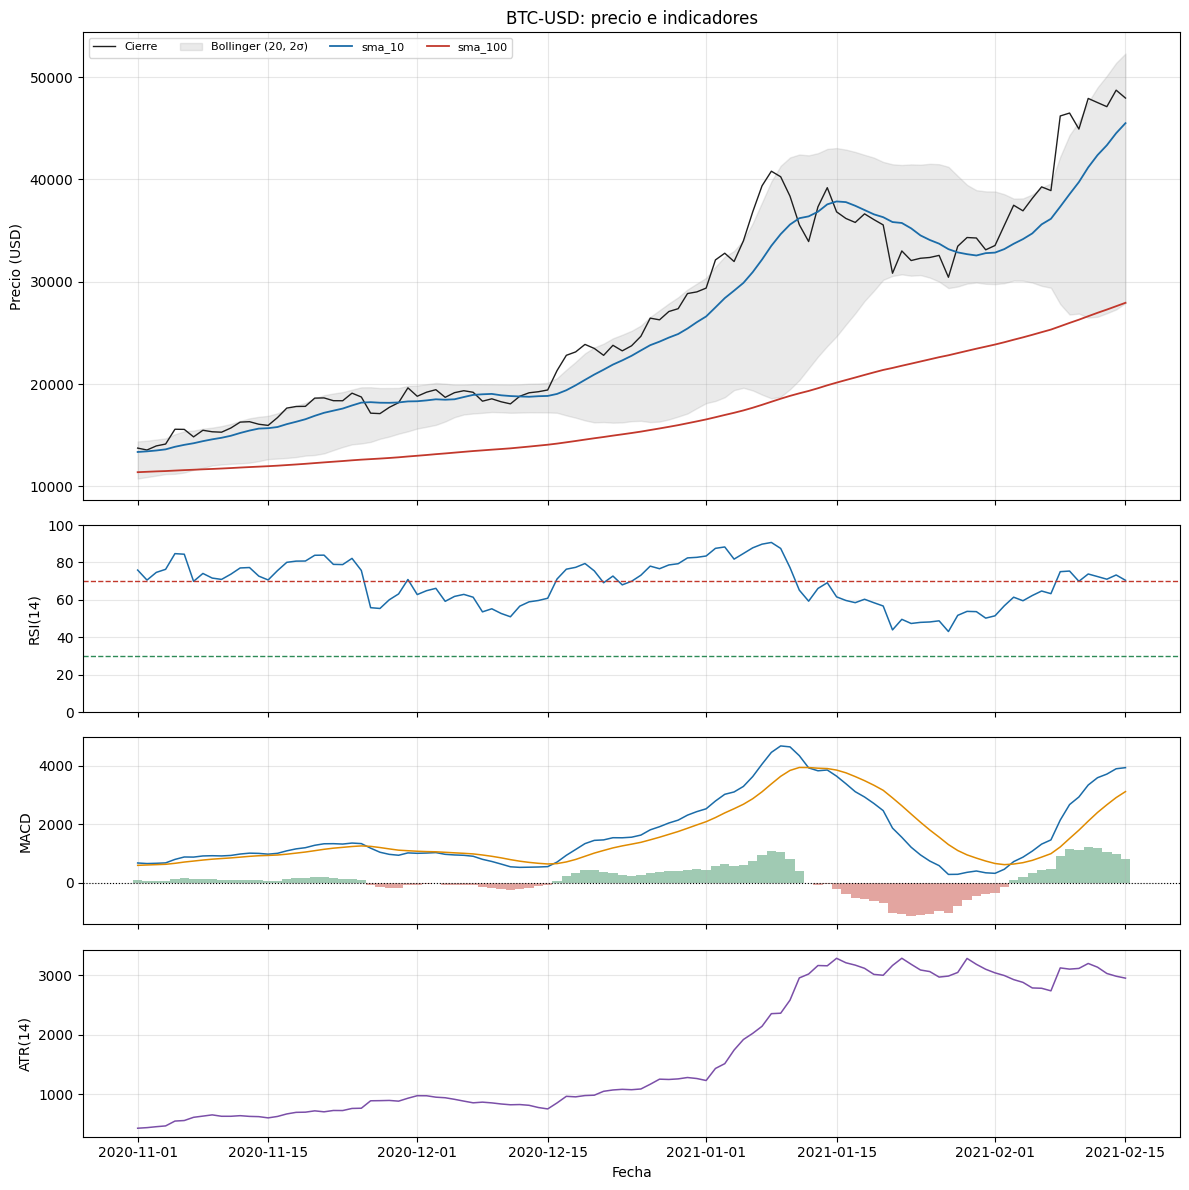

In [19]:
fig = plot_panel(out.loc["2020-11-01":"2021-02-15"])
fig

Del 17 al 20 de diciembre de 2020 el RSI estuvo entre 75 y 79, o sea
sobrecompra clara. Vender ahi habria significado perderse un +71% en los
siguientes 20 dias, porque BTC paso de 23,000 a 40,000 en tres semanas.

El RSI no esta mal calculado, esta mal interpretado. La sobrecompra solo
implica reversion cuando el mercado esta lateral. En una tendencia fuerte el
RSI se queda arriba de 70 durante semanas y el nivel deja de ser informativo.

### MACD

In [20]:
s = np.sign(out["macd"] - out["macd_signal"])
cruces_alcistas = out.index[s.diff() == 2]

cm = pd.DataFrame({"fwd20": fwd[cruces_alcistas]}).dropna()
mal = cm[cm["fwd20"] < -0.12]

print(f"cruces alcistas: {len(cm)}")
print(f"seguidos de -12% en 20 dias: {len(mal)} ({100 * len(mal) / len(cm):.0f}%)")
mal.sort_values("fwd20").head()

cruces alcistas: 84
seguidos de -12% en 20 dias: 11 (13%)


,fwd20
Date,
2021-04-30,-0.293808
2022-05-04,-0.252977
2021-09-06,-0.179068
2022-08-08,-0.176092
2023-02-17,-0.171076


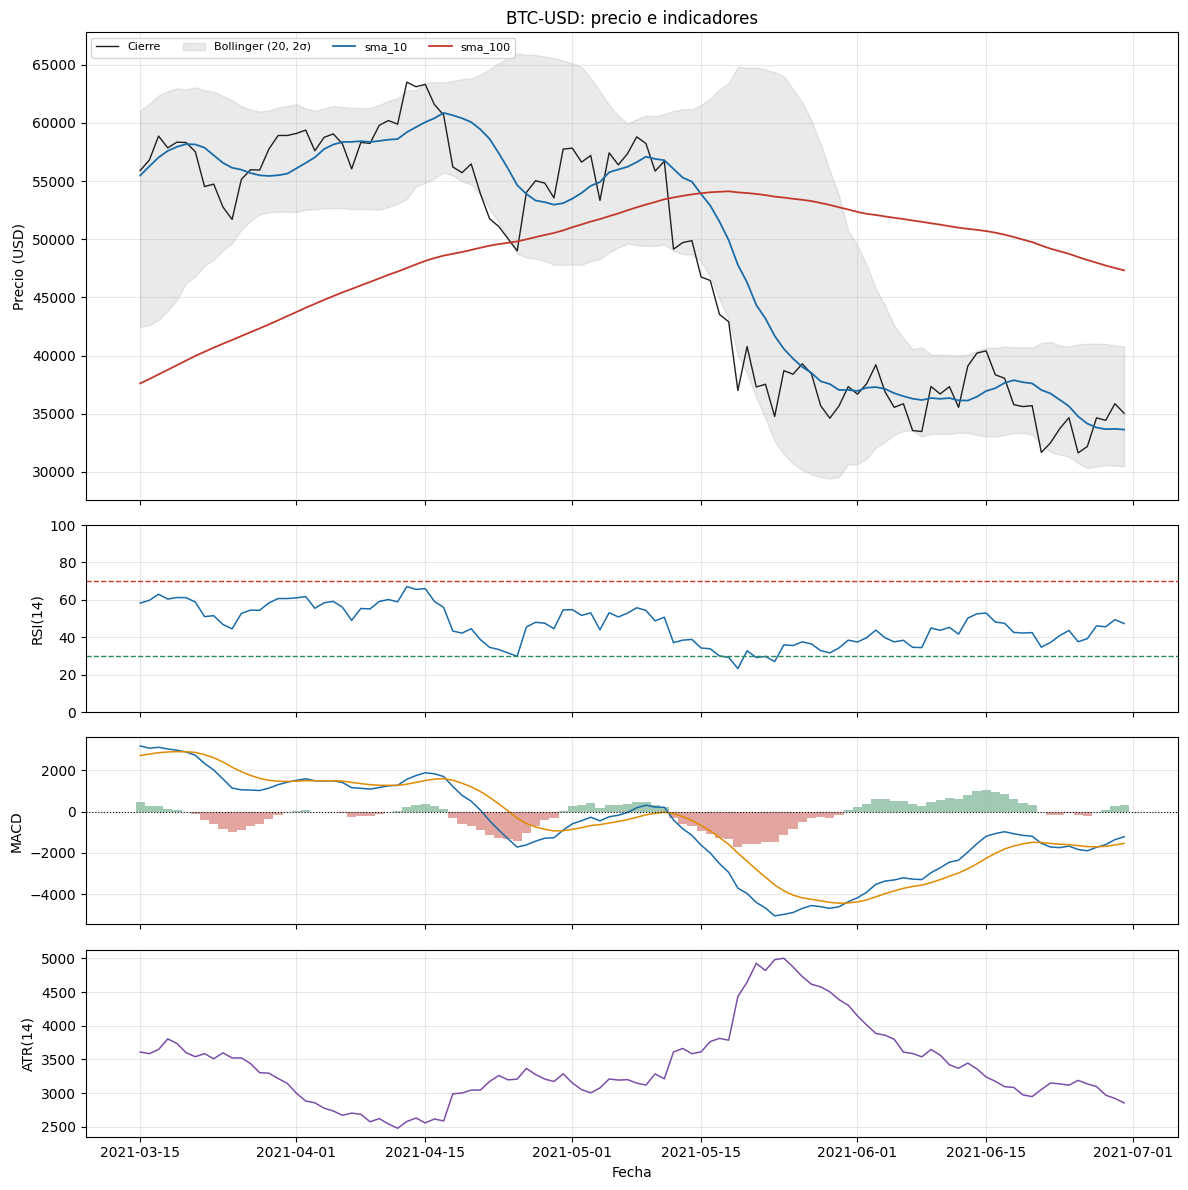

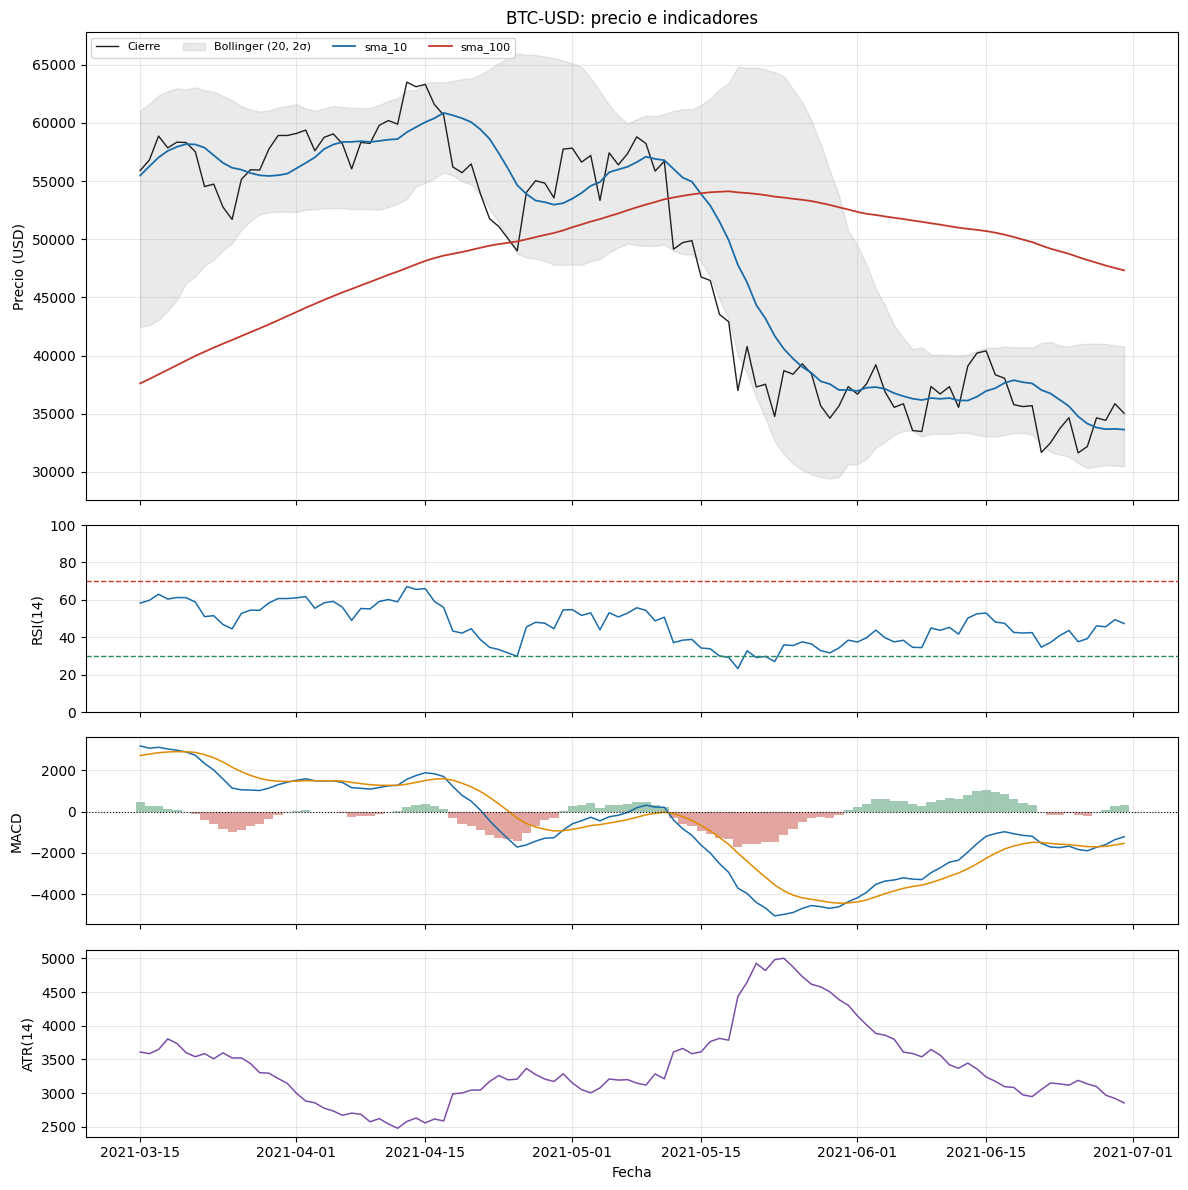

In [21]:
fig = plot_panel(out.loc["2021-03-15":"2021-06-30"])
fig

El 30 de abril de 2021 el MACD cruzo al alza su linea de señal, que es una
señal de compra tipica, y el precio cayo 29.4% en 20 dias. Era el inicio del
desplome de mayo 2021, de 58,000 a 35,000.

El MACD es la diferencia de dos EMAs, por lo que arrastra doble rezago. Para
cuando el cruce ocurre, el movimiento que lo genero ya paso.

### Bollinger

In [22]:
over = (out["close"] > out["bb_high"]).astype(int)
g = (over != over.shift()).cumsum()
runs = (out[over == 1].groupby(g[over == 1])
        .apply(lambda x: pd.Series({
            "ini": x.index[0], "fin": x.index[-1], "dias": len(x),
            "ret_%": 100 * (x["close"].iloc[-1] / x["close"].iloc[0] - 1)})))
runs.sort_values("dias", ascending=False).head()

,ini,fin,dias,ret_%
80,2023-01-08,2023-01-16,9,23.863167
112,2024-02-08,2024-02-14,7,14.403760
98,2023-10-20,2023-10-25,6,16.237844
18,2020-07-25,2020-07-30,6,14.819508
170,2026-08-19,2026-08-23,5,12.255732


Del 8 al 16 de enero de 2023 el precio cerro 9 dias seguidos por encima de la
banda superior y subio 23.9% durante esa racha. Interpretarlo como "toco la
banda alta, entonces vendo" habria costado todo el tramo.

Es el mismo error que con el RSI. Las bandas suponen que el precio regresa a la
media, pero en un breakout el precio camina pegado a la banda y la banda lo
persigue en vez de contenerlo.

### Las medias moviles

In [23]:
s = np.sign(out["close"] - out["sma_10"])
ch = (s.diff() != 0).astype(int)
w = ch.rolling(60).sum()
t = w.idxmax()
ini = t - pd.Timedelta(days=59)
tramo = out.loc[ini:t]

print(f"peor ventana de 60 dias: {ini.date()} a {t.date()}")
print(f"cruces con la sma_10: {int(w.max())}")
print(f"precio: {tramo.close.iloc[0]:,.0f} -> {tramo.close.iloc[-1]:,.0f} "
      f"({100 * (tramo.close.iloc[-1] / tramo.close.iloc[0] - 1):+.1f}%)")
print(f"ADX promedio: {tramo.adx.mean():.1f}  (global: {out.adx.mean():.1f})")

peor ventana de 60 dias: 2023-04-09 a 2023-06-07
cruces con la sma_10: 22
precio: 28,333 -> 26,346 (-7.0%)
ADX promedio: 22.6  (global: 29.3)


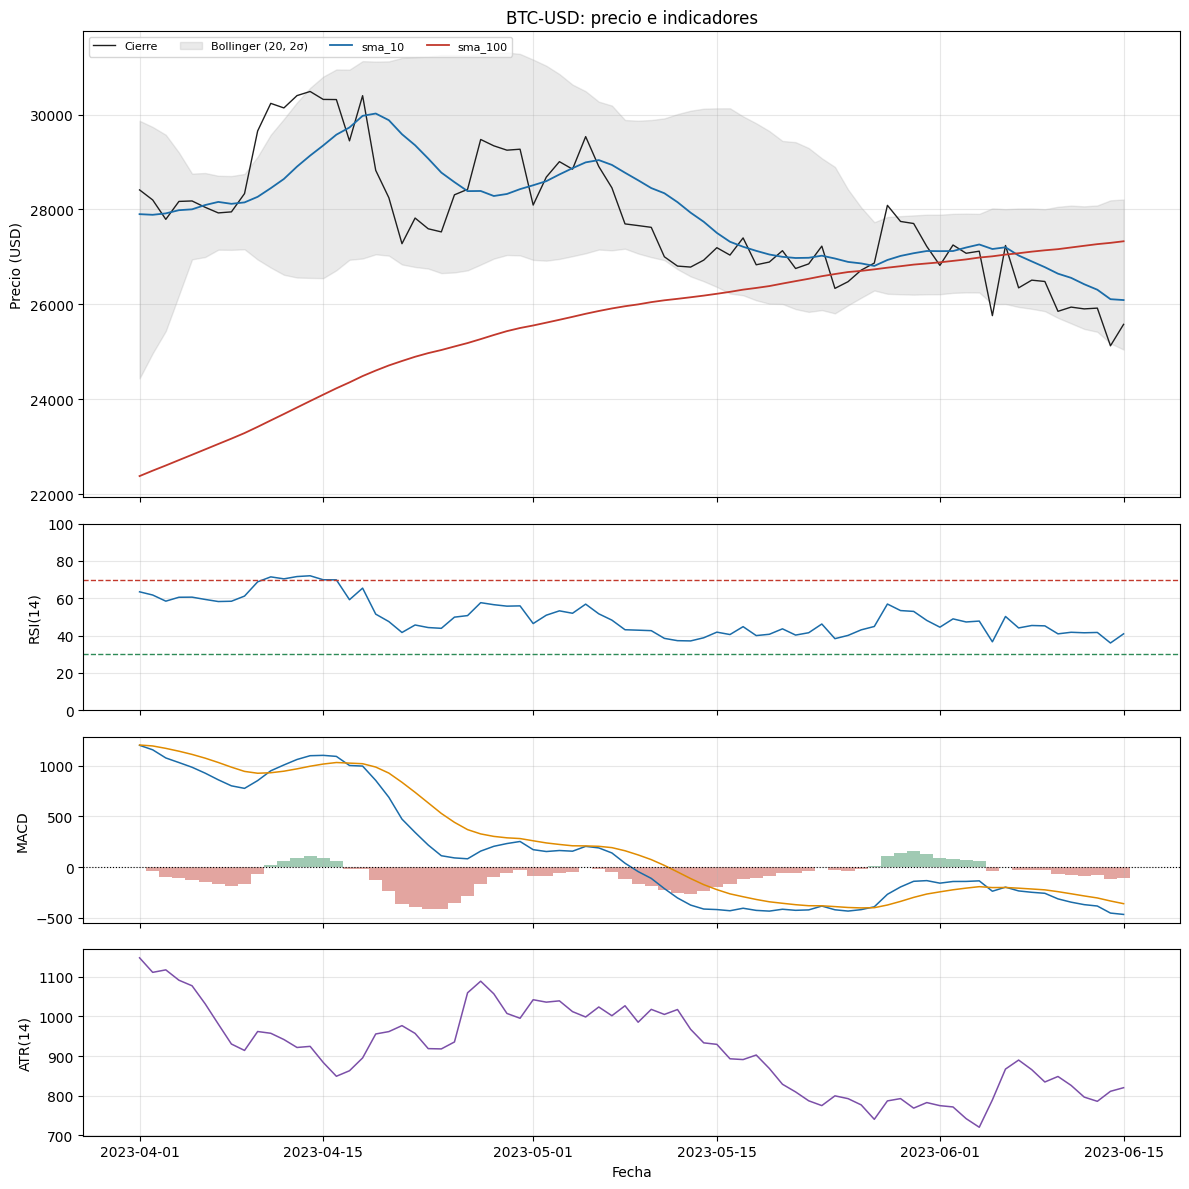

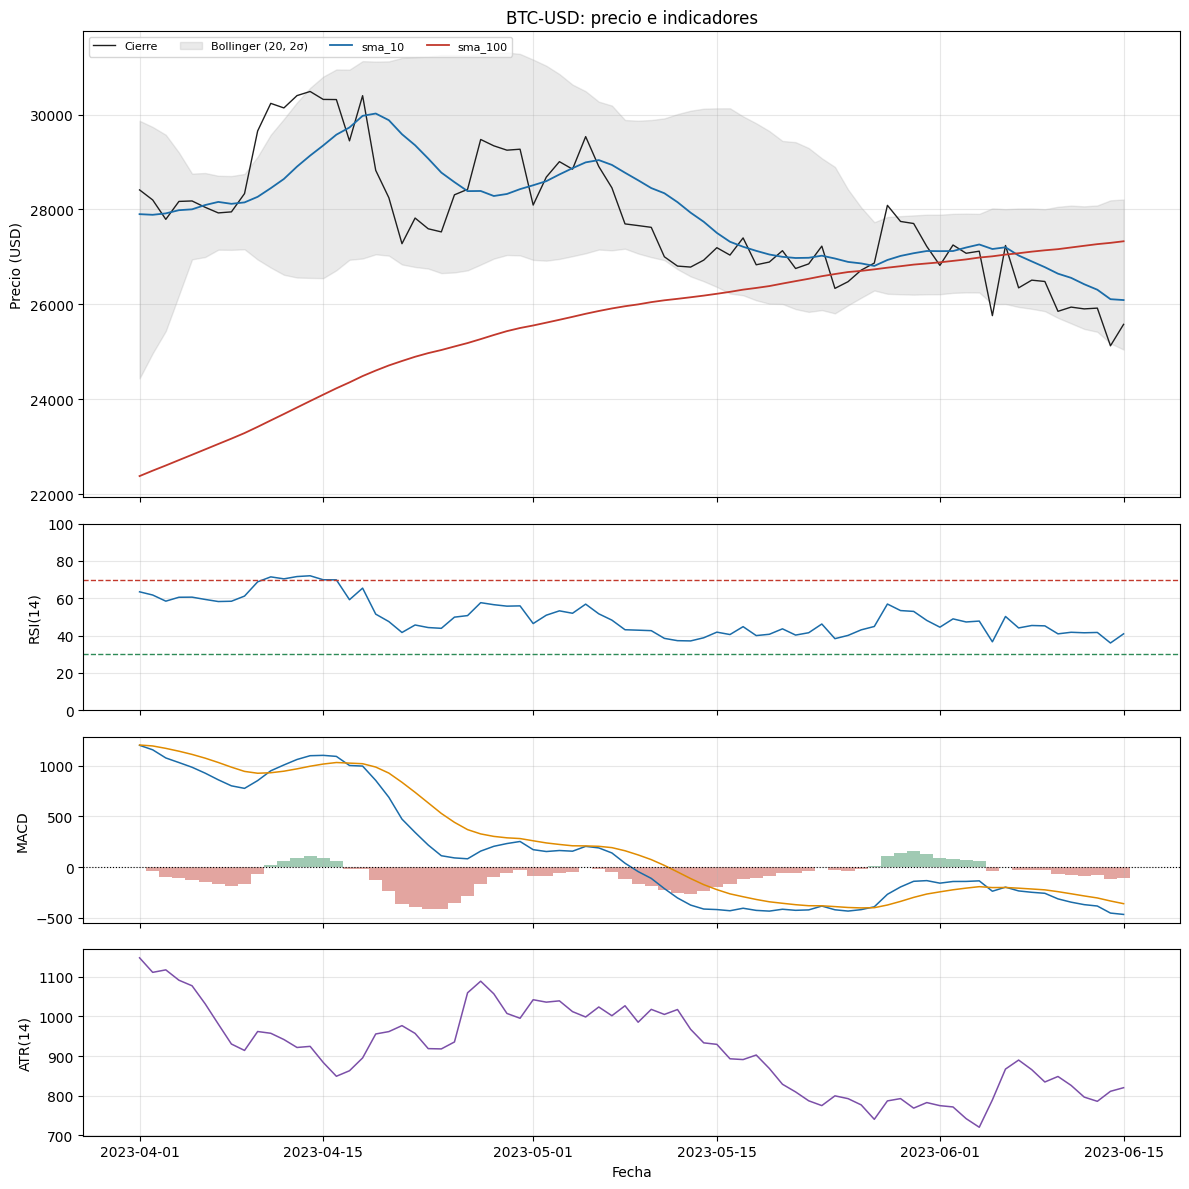

In [24]:
fig = plot_panel(out.loc["2023-04-01":"2023-06-15"])
fig

Del 9 de abril al 7 de junio de 2023 el precio cruzo la `sma_10` 22 veces en 60
dias, o sea una señal cada 2.7 dias, y al final quedo en -7%. Solo costo de
transaccion, sin movimiento que capturar.

### Lo que note

In [25]:
print(f"ADX en el tramo del RSI fallido (dic 2020):  "
      f"{out.loc['2020-12-17':'2021-01-08', 'adx'].mean():.1f}")
print(f"ADX en el lateral de 2023 (sma_10 agitada): "
      f"{out.loc['2023-04-09':'2023-06-07', 'adx'].mean():.1f}")
print(f"ADX promedio global:                         {out['adx'].mean():.1f}")
print()
print(f"ventanas con muchos cruces (15 o mas): ADX {out.adx[w >= 15].mean():.1f}")
print(f"ventanas con pocos cruces (5 o menos): ADX {out.adx[w <= 5].mean():.1f}")

ADX en el tramo del RSI fallido (dic 2020):  46.8
ADX en el lateral de 2023 (sma_10 agitada): 22.6
ADX promedio global:                         29.3

ventanas con muchos cruces (15 o mas): ADX 26.7
ventanas con pocos cruces (5 o menos): ADX 35.8


Con ADX alto hay tendencia y fallan los osciladores: el RSI y las bandas marcan
sobrecompra mientras el precio sigue subiendo.

Con ADX bajo el mercado esta lateral y fallan las medias y el MACD, que dan
cruces sin contenido.

El ADX por si solo no dice si comprar o vender, pero si
indica cual de los otros indicadores va a fallar.

## Pregunta 3: que tan parecidos son entre si

La matriz de la pista es la de correlacion.

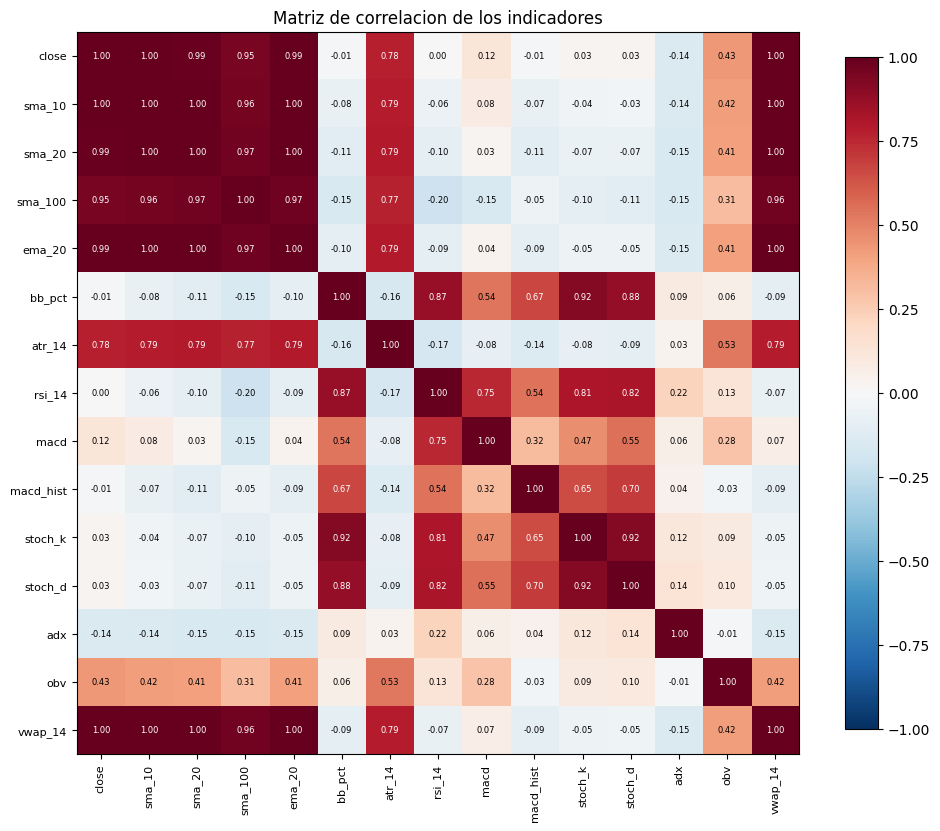

In [26]:
cols = ["close", "sma_10", "sma_20", "sma_100", "ema_20", "bb_pct", "atr_14",
        "rsi_14", "macd", "macd_hist", "stoch_k", "stoch_d", "adx", "obv", "vwap_14"]
corr = out[cols].dropna().corr()

fig = plot_corr(out[cols].dropna())
guardar(fig, "outputs/05_corr.png")
fig

In [27]:
c = corr.abs()
pares = (c.where(np.triu(np.ones(c.shape), 1).astype(bool))
         .stack().sort_values(ascending=False))
pares[pares > 0.85]

sma_20   ema_20     0.999626
sma_10   vwap_14    0.999588
ema_20   vwap_14    0.999353
sma_20   vwap_14    0.999028
sma_10   ema_20     0.998701
         sma_20     0.997865
close    sma_10     0.996431
         vwap_14    0.995220
         ema_20     0.994088
         sma_20     0.992098
sma_100  ema_20     0.969564
sma_20   sma_100    0.968343
sma_100  vwap_14    0.963080
sma_10   sma_100    0.960031
close    sma_100    0.951628
stoch_k  stoch_d    0.920414
bb_pct   stoch_k    0.919080
         stoch_d    0.880300
         rsi_14     0.869893
dtype: float64

Se distinguen dos bloques.

El primero es `close`, `sma_10`, `sma_20`, `ema_20` y `vwap_14`, todos entre
0.99 y 1.00. Son la misma serie con distinto suavizado. La `sma_20` y la
`ema_20` dan 1.000, asi que usar las dos no aporta nada. La `sma_100` baja a
0.95 y 0.97 solo porque tiene mas rezago.

El segundo es `rsi_14`, `stoch_k`, `stoch_d`, `bb_pct` y `macd`. El par
`bb_pct` con `stoch_k` da 0.92 y `rsi_14` con `bb_pct` da 0.87. Tiene sentido
porque los tres miden lo mismo, que es donde esta el precio dentro de su rango
reciente. Cambia la formula pero no la idea.

Los unicos dos que aportan informacion distinta son el `adx`, que sale casi en
0 contra todo porque mide fuerza y no direccion, y el `obv` con 0.43, que es el
unico que usa volumen.

Sale 0.79 contra el precio, lo que pareceria indicar que
la volatilidad sube cuando sube el precio. Pero el ATR esta en dolares y BTC
paso de 5,000 a 124,000, asi que cualquier medida en dolares crece con el
nivel.

In [28]:
print(f"corr(atr_14,       close) = {out['atr_14'].corr(out['close']):+.3f}")
print(f"corr(atr_14/close, close) = "
      f"{(out['atr_14'] / out['close']).corr(out['close']):+.3f}")

corr(atr_14,       close) = +0.791
corr(atr_14/close, close) = -0.162


Dividiendolo entre el precio, la correlacion baja a -0.16. Es decir que la
volatilidad en porcentaje no depende del nivel de BTC. Me sirvio para notar que
una matriz de correlacion sobre series con tendencia mide sobre todo la
tendencia comun, no que las variables esten relacionadas.

### Respuesta

De las 15 columnas hay como 4 ideas distintas: nivel de precio, momentum,
fuerza de tendencia y volumen. Agregar mas medias moviles u osciladores no
aporta informacion, solo agrega columnas.

## Pregunta 4: alguno mira al futuro

La prueba que pide la consigna es recalcular el indicador sobre `df.iloc[:t+1]`
y comparar el valor en t contra el de la muestra completa. Si cambian, hay
look-ahead.

La funcion `check_lookahead` esta en `src/indicators.py`. Recibe el df, una
funcion que devuelve una serie, y una lista de posiciones t.

In [29]:
ts = [150, 400, 800, 1200, 1600, 2000, 2400]

pruebas = {
    "sma_10": lambda d: sma(d, 10),
    "ema_20": lambda d: ema(d, 20),
    "rsi_14": lambda d: rsi(d, 14),
    "atr_14": lambda d: atr(d, 14),
    "macd": lambda d: macd(d)["macd"],
    "stoch_k": lambda d: stochastic(d)["stoch_k"],
    "adx": lambda d: adx(d)["adx"],
    "obv": lambda d: obv(d),
    "vwap_14": lambda d: vwap(d, 14),
}

resumen = pd.DataFrame({
    nombre: {"dif_max": check_lookahead(df, fn, ts)["dif_abs"].max()}
    for nombre, fn in pruebas.items()
}).T
resumen

,dif_max
sma_10,0.0
ema_20,0.0
rsi_14,0.0
atr_14,0.0
macd,0.0
stoch_k,0.0
adx,0.0
obv,0.0
vwap_14,0.0


Los 9 dan diferencia exactamente 0. Ninguno de los indicadores que use mira al
futuro.

Esto tiene sentido si se piensa como estan construidos. Todos son ventanas
moviles o recursiones hacia atras, entonces el valor en t solo depende de las
barras hasta t. Quitar lo que viene despues no cambia nada.

Aqui esperaba que el EMA, el RSI, el ATR y el MACD si cambiaran un poco, porque
son recursivos y pense que el arranque de la recursion los movia. Pero no pasa:
`df.iloc[:t+1]` conserva toda la historia desde la primera barra, asi que la
recursion empieza en el mismo lugar en los dos casos. Lo unico que se le quita
es el futuro. Habria diferencia si cortara el inicio en vez del final, pero esa
ya seria otra prueba.

In [30]:
check_lookahead(df, lambda d: rsi(d, 14), ts)

,fecha,completa,hasta_t,dif_abs,dif_rel_%
t,,,,,
150,2020-05-30,60.404356,60.404356,0.0,0.0
400,2021-02-04,59.546098,59.546098,0.0,0.0
800,2022-03-11,46.038783,46.038783,0.0,0.0
1200,2023-04-15,69.915982,69.915982,0.0,0.0
1600,2024-05-19,56.330681,56.330681,0.0,0.0
2000,2025-06-23,51.987558,51.987558,0.0,0.0
2400,2026-07-28,48.393173,48.393173,0.0,0.0


### Un caso que si tiene look-ahead

Para comprobar que la prueba sirve y no siempre da 0, meto a proposito dos
indicadores mal hechos.

El primero es una media movil centrada. En vez de promediar las 20 barras
anteriores, promedia 10 hacia atras y 10 hacia adelante.

In [31]:
t = 1000
print("media centrada en t =", t)
print("  con la muestra completa:", round(centered_ma(df, 20).iloc[t], 2))
print("  con datos hasta t     :", centered_ma(df.iloc[:t + 1], 20).iloc[-1])

media centrada en t = 1000
  con la muestra completa: 19408.86
  con datos hasta t     : nan


Con la muestra completa tiene valor, y con datos hasta t da NaN. Ni siquiera se
puede calcular en tiempo real, porque le faltan las 10 barras que todavia no
existen.

El segundo es un z-score que normaliza con la media y la desviacion de toda la
muestra.

In [32]:
check_lookahead(df, zscore_muestra, ts)

,fecha,completa,hasta_t,dif_abs,dif_rel_%
t,,,,,
150,2020-05-30,-1.299874,1.085419,2.385294,183.501849
400,2021-02-04,-0.417722,2.996770,3.414492,817.407136
800,2022-03-11,-0.357167,0.446437,0.803603,224.993804
1200,2023-04-15,-0.631818,0.113587,0.745405,117.977823
1600,2024-05-19,0.533336,2.071590,1.538254,288.420939
2000,2025-06-23,1.806696,2.434425,0.627729,34.744558
2400,2026-07-28,0.455346,0.466464,0.011118,2.441749


Este si se puede calcular siempre, pero da valores distintos. En t = 500 la
muestra completa dice -0.10 y con datos hasta t dice +1.42, una diferencia de
1.5 desviaciones. El problema es que la media y la desviacion de toda la
muestra incluyen precios que en t todavia no habian pasado.

Es el error mas facil de cometer sin darse cuenta, porque el indicador se ve
normal y no marca ningun error.

### Respuesta

Ninguno de mis 9 indicadores mira al futuro, la diferencia es 0 en todos. Los
dos casos que si fallan los agregue yo a proposito para verificar que la prueba
detecta el problema cuando existe.